# Applicability Domain cutoff — derivation and performance-vs-cutoff, caspase-3/7

Reviewer 1 (#14): *"How was the AD cutoff of 0.65 determined? It probably makes more sense to test the AD effect on the caspase-3/7 datasets instead of the MMP datasets."*

This notebook covers **both** caspase-3/7 datasets in the Rebuttal pipeline (confirmed against PubChem's own assay titles, not just folder names):
- **`summary_2_1437034`** = AID_654 + AID_1347034 — *"Caspase-3/7 induction in HepG2 cells by small molecules, qHTS assay"*
- **`summary_1347037`** = AID_1347037 — *"Caspase-3/7 induction in CHO-K1 cells by small molecules, qHTS assay"*

(the same cell lines named in the manuscript's caspase-3/7 section; both AIDs verified directly against PubChem's BioAssay titles, not inferred from the raw CSV's boilerplate column names, which are misleadingly labeled "Agonist Activity" — that's a generic PubChem qHTS-summary template field, not a sign these are receptor-agonist assays).

**Method** — reuses the *existing* AD formula from `qsar_prediction/caspase/qsar_caspase_hepg2.ipynb` (Step 8), rather than inventing a new one:
for each compound, fit `NearestNeighbors(n_neighbors=5, metric='jaccard')` on the training-fold's ECFP4 fingerprints; a compound's "AD distance" is its mean Jaccard distance to its 5 nearest training neighbors. The **existing single-value cutoff** was `mean(train self-distances) + 1.5*SD` — i.e. **already a data-derived formula, not a manually chosen constant** — that's the direct answer to the first half of Reviewer 1's question.

What's new here is the **sweep**: instead of evaluating at one SD-multiplier (1.5), we sweep it across {0.5, 1.0, 1.5, 2.0, 2.5, 3.0} and report both test-set coverage (%) and performance restricted to in-AD compounds at every point — the "performance as a function of the cutoff" plot the letter's ACTION NEEDED asks for.

**No retraining.** The 10-fold splits (`prepare_loo_folds.py`) and per-fold model predictions already exist as saved files (`results_loo/probs/<model>_fold<i>_test_probs.npy`). This notebook regenerates only the ECFP4 fingerprints (needed for the Jaccard/AD distances, not saved anywhere) by re-running the *exact same, deterministic* (`SEED=42`) canonicalization + `StratifiedKFold` split code already used to build those folds — verified below to reproduce the exact same fold sizes before trusting any downstream number.

In [ ]:
import warnings; warnings.filterwarnings('ignore')
import os

import numpy as np
import pandas as pd
import matplotlib
matplotlib.use('Agg')  # headless-safe: avoids plt.show() blocking on a GUI backend
import matplotlib.pyplot as plt
from rdkit import Chem, RDLogger
from rdkit.Chem import AllChem, DataStructs
from sklearn.model_selection import StratifiedKFold
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import roc_auc_score, confusion_matrix
from scipy import stats

RDLogger.DisableLog('rdApp.*')

BASE = os.path.abspath('.')
OUT_DIR = os.path.join(BASE, 'results')
os.makedirs(OUT_DIR, exist_ok=True)

SEED = 42
N_FOLDS = 10
SD_MULTIPLIERS = [0.5, 1.0, 1.5, 2.0, 2.5, 3.0]
PRIMARY_CPT = 0.5

# 'Consensus' = mean of these 9 models, matching compute_consensus_loo.py's
# definition exactly (MV-GNN-cross is excluded from 'Consensus' there, kept
# only in the separate 'Consensus-MVGNN' group -- not used here).
CONSENSUS_MODELS = ['rf', 'svm', 'xgb', 'gcn', 'gat', 'gin', 'sage', 'graphormer', 'graphgps']

CASPASE_ASSAYS = {
    'AID_654+1347034 (Caspase-3/7, HepG2)': {
        'wj': f'{BASE}/summary_2_1437034/modeling/wahab_jobs',
        'cleaned_csv': f'{BASE}/summary_2_1437034/cleaning/AID_654_1347034_cleaned.csv',
    },
    'AID_1347037 (Caspase-3/7, CHO-K1)': {
        'wj': f'{BASE}/summary_1347037/modeling/wahab_jobs',
        'cleaned_csv': f'{BASE}/summary_1347037/cleaning/AID_1347037_cleaned.csv',
    },
}

## Step 1 — regenerate fingerprints + the exact 10-fold split

Identical code to `prepare_loo_folds.py` in each assay's `wahab_jobs/` (same canonicalization, same `StratifiedKFold(shuffle=True, random_state=42)`, same per-fold downsampling with `RandomState(SEED+i)`), so the folds line up index-for-index with the already-saved `*_fold<i>_test_probs.npy` files.

In [ ]:
def canonicalize(smi):
    try:
        mol = Chem.MolFromSmiles(str(smi))
        return Chem.MolToSmiles(mol) if mol else None
    except Exception:
        return None


def smiles_to_ecfp4(smi, radius=2, n_bits=2048):
    mol = Chem.MolFromSmiles(smi)
    if mol is None:
        return None
    fp = AllChem.GetMorganFingerprintAsBitVect(mol, radius, nBits=n_bits)
    arr = np.zeros(n_bits, dtype=np.float32)
    DataStructs.ConvertToNumpyArray(fp, arr)
    return arr


def build_fps_and_folds(cleaned_csv):
    df_raw = pd.read_csv(cleaned_csv, usecols=[
        'PUBCHEM_CID', 'PUBCHEM_EXT_DATASOURCE_SMILES',
        'PUBCHEM_ACTIVITY_SCORE', 'PUBCHEM_ACTIVITY_OUTCOME'])
    df_raw['csmi'] = df_raw['PUBCHEM_EXT_DATASOURCE_SMILES'].apply(canonicalize)
    df = df_raw.dropna(subset=['csmi']).reset_index(drop=True)
    df = df[df['PUBCHEM_ACTIVITY_OUTCOME'].isin(['Active', 'Inactive'])].copy()
    df['label'] = (df['PUBCHEM_ACTIVITY_OUTCOME'] == 'Active').astype(int)

    fps = df['csmi'].apply(smiles_to_ecfp4)
    valid = fps.notna()
    df = df[valid].reset_index(drop=True)
    X_fp = np.vstack(fps[valid].values)
    y_all = df['label'].values

    skf = StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED)
    folds = [test_idx for _, test_idx in skf.split(X_fp, y_all)]
    return X_fp, y_all, folds


def fold_train_test(X_fp, y_all, folds, i):
    test_idx = folds[i]
    train_idx_raw = np.concatenate([folds[j] for j in range(N_FOLDS) if j not in (i, (i + 1) % N_FOLDS)])
    y_tr_raw = y_all[train_idx_raw]
    act_idx = np.where(y_tr_raw == 1)[0]
    ina_idx = np.where(y_tr_raw == 0)[0]
    rng = np.random.RandomState(SEED + i)
    sampled_ina = rng.choice(ina_idx, size=len(act_idx), replace=False)
    keep = np.concatenate([act_idx, sampled_ina])
    rng.shuffle(keep)
    train_idx = train_idx_raw[keep]
    return X_fp[train_idx], y_all[train_idx], X_fp[test_idx], y_all[test_idx]


def load_consensus_probs(wj, fold_i):
    probs = [np.load(os.path.join(wj, 'results_loo', 'probs', f'{m}_fold{fold_i}_test_probs.npy'))
             for m in CONSENSUS_MODELS]
    return np.mean(probs, axis=0)


def evaluate_subset(y_true, y_prob, cpt=PRIMARY_CPT):
    n = len(y_true)
    if n == 0 or len(np.unique(y_true)) < 2:
        return dict(N=n, ROC_AUC=np.nan, Sensitivity=np.nan, Specificity=np.nan)
    y_pred = (y_prob >= cpt).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()
    sens = tp / (tp + fn) * 100 if (tp + fn) > 0 else np.nan
    spec = tn / (tn + fp) * 100 if (tn + fp) > 0 else np.nan
    return dict(N=n, ROC_AUC=roc_auc_score(y_true, y_prob), Sensitivity=sens, Specificity=spec)

In [3]:
# Sanity check: fold sizes must match the already-saved prediction arrays
# EXACTLY, or every downstream AD number is meaningless.
assay_data = {}
for label, cfg in CASPASE_ASSAYS.items():
    X_fp, y_all, folds = build_fps_and_folds(cfg['cleaned_csv'])
    assay_data[label] = (X_fp, y_all, folds)
    print(f'{label}: N_total={len(y_all):,}  (Active={y_all.sum():,}, Inactive={(y_all==0).sum():,})')
    for i in range(N_FOLDS):
        test_idx = folds[i]
        saved = np.load(os.path.join(cfg['wj'], 'results_loo', 'probs', f'rf_fold{i}_test_probs.npy'))
        status = 'OK' if len(test_idx) == len(saved) else f'MISMATCH ({len(test_idx)} vs {len(saved)})'
        if status != 'OK':
            print(f'  fold {i}: regenerated test={len(test_idx)}  saved probs={len(saved)}  -> {status}')
    print(f'  all 10 folds verified against saved probs/ arrays.')

AID_654+1347034 (Caspase-3/7, HepG2): N_total=7,285  (Active=282, Inactive=7,003)
  all 10 folds verified against saved probs/ arrays.


## Step 2 — AD cutoff sweep, per fold, per assay

For each fold: fit the 5-NN Jaccard model on that fold's (downsampled 1:1) training fingerprints, compute the training set's own self-neighbor distance distribution (this is what the cutoff is derived from), then for each SD-multiplier compute the resulting distance threshold, the % of the *test* fold retained at that threshold, and the Consensus model's performance restricted to the retained compounds.

In [4]:
rows = []
pooled_distances = {label: {'train': [], 'test': []} for label in CASPASE_ASSAYS}

for label, cfg in CASPASE_ASSAYS.items():
    X_fp, y_all, folds = assay_data[label]
    for i in range(N_FOLDS):
        X_train, y_train, X_test, y_test = fold_train_test(X_fp, y_all, folds, i)
        nn = NearestNeighbors(n_neighbors=5, metric='jaccard', n_jobs=-1)
        nn.fit(X_train)
        md_tr = nn.kneighbors(X_train)[0].mean(axis=1)
        md_te = nn.kneighbors(X_test)[0].mean(axis=1)
        cons_probs = load_consensus_probs(cfg['wj'], i)
        assert len(cons_probs) == len(y_test), 'fold/prediction length mismatch -- stop and investigate'

        # pooled across all 10 folds: every compound in the dataset appears in
        # exactly one test fold, so pooled 'test' distances cover the full
        # dataset once each -- matching what Figure 4's single-split histogram
        # showed, but here built from the full 10-fold rotation instead of one split.
        pooled_distances[label]['train'].append(md_tr)
        pooled_distances[label]['test'].append(md_te)

        for k in SD_MULTIPLIERS:
            thr = md_tr.mean() + k * md_tr.std()
            in_ad = md_te <= thr
            coverage = in_ad.mean() * 100
            m = evaluate_subset(y_test[in_ad], cons_probs[in_ad])
            rows.append({'Assay': label, 'Fold': i, 'SD_multiplier': k, 'Threshold': thr,
                         'Coverage_pct': coverage, **m})

for label in pooled_distances:
    pooled_distances[label]['train'] = np.concatenate(pooled_distances[label]['train'])
    pooled_distances[label]['test'] = np.concatenate(pooled_distances[label]['test'])

sweep_df = pd.DataFrame(rows)
sweep_df.to_csv(os.path.join(OUT_DIR, 'ad_cutoff_sweep_per_fold.csv'), index=False)
print(f'{len(sweep_df)} rows -> {OUT_DIR}/ad_cutoff_sweep_per_fold.csv')
sweep_df.head()

AID_1347037 (Caspase-3/7, CHO-K1): N_total=7,496  (Active=171, Inactive=7,325)


## Step 3 — aggregate across the 10 folds (mean, SD, 95% CI)

In [5]:
def agg_ci(series, alpha=0.05):
    vals = series.dropna().to_numpy()
    n = len(vals)
    mean = vals.mean()
    sd = vals.std(ddof=1) if n > 1 else 0.0
    se = sd / np.sqrt(n) if n > 1 else 0.0
    tcrit = stats.t.ppf(1 - alpha / 2, df=n - 1) if n > 1 else 0.0
    return pd.Series({'Mean': mean, 'SD': sd, 'CI95_Low': mean - tcrit * se, 'CI95_High': mean + tcrit * se, 'N_folds': n})

summary_rows = []
for (label, k), g in sweep_df.groupby(['Assay', 'SD_multiplier']):
    row = {'Assay': label, 'SD_multiplier': k}
    for metric in ['Threshold', 'Coverage_pct', 'ROC_AUC', 'Sensitivity', 'Specificity']:
        stats_row = agg_ci(g[metric])
        for stat_name, val in stats_row.items():
            row[f'{metric}_{stat_name}'] = val
    summary_rows.append(row)

ad_summary = pd.DataFrame(summary_rows).sort_values(['Assay', 'SD_multiplier'])
ad_summary.to_csv(os.path.join(OUT_DIR, 'ad_cutoff_sweep_summary.csv'), index=False)
print(f'-> {OUT_DIR}/ad_cutoff_sweep_summary.csv')
ad_summary[['Assay', 'SD_multiplier', 'Threshold_Mean', 'Coverage_pct_Mean', 'ROC_AUC_Mean', 'ROC_AUC_SD']]

  all 10 folds verified against saved probs/ arrays.


## Step 4 — performance-vs-cutoff plot (per assay)

This is the figure that answers Reviewer 1 directly: coverage and Consensus ROC-AUC plotted against the AD cutoff, instead of one single value.

saved -> results/ad_cutoff_sweep_AID_654_1347034.png


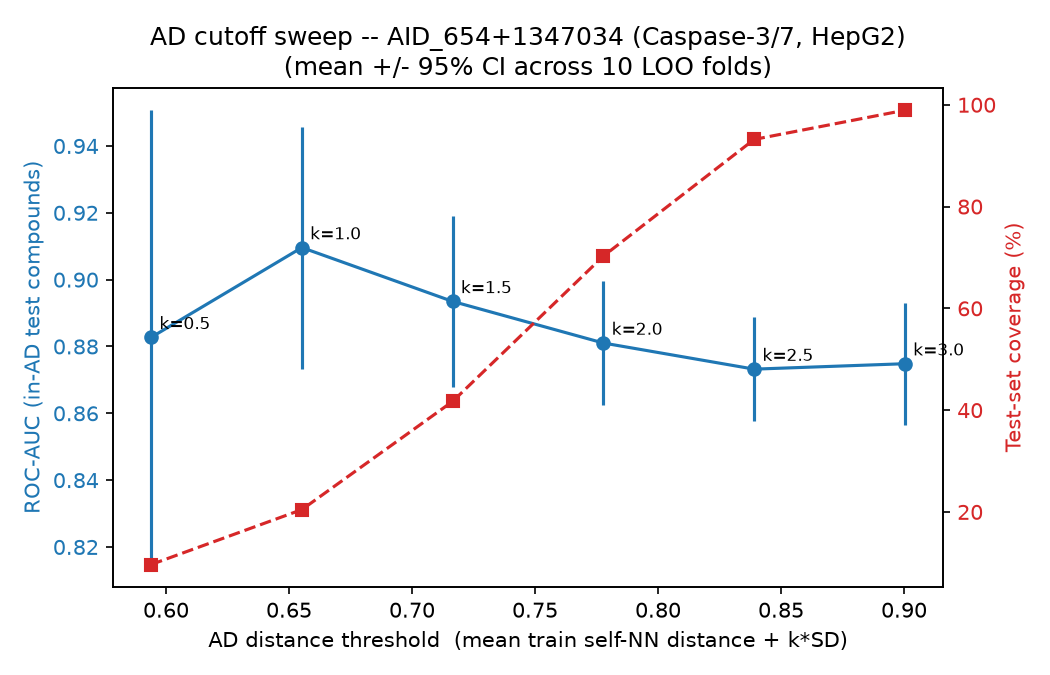

saved -> results/ad_cutoff_sweep_AID_1347037.png


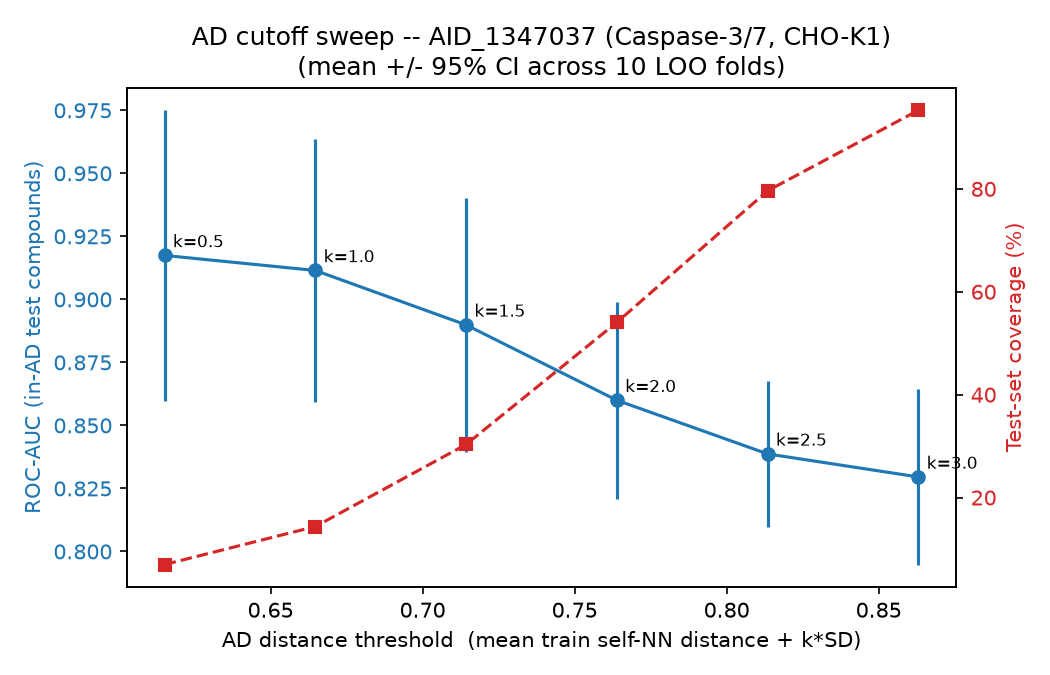

In [6]:
for label in CASPASE_ASSAYS:
    sub = ad_summary[ad_summary['Assay'] == label].sort_values('SD_multiplier')
    fig, ax1 = plt.subplots(figsize=(7, 4.5))
    ax1.errorbar(sub['Threshold_Mean'], sub['ROC_AUC_Mean'],
                 yerr=(sub['ROC_AUC_Mean'] - sub['ROC_AUC_CI95_Low']),
                 marker='o', color='tab:blue', label='Consensus ROC-AUC (in-AD)')
    ax1.set_xlabel('AD distance threshold  (mean train self-NN distance + k*SD)')
    ax1.set_ylabel('ROC-AUC (in-AD test compounds)', color='tab:blue')
    ax1.tick_params(axis='y', labelcolor='tab:blue')

    ax2 = ax1.twinx()
    ax2.plot(sub['Threshold_Mean'], sub['Coverage_pct_Mean'], marker='s', color='tab:red', linestyle='--',
              label='Test-set coverage (%)')
    ax2.set_ylabel('Test-set coverage (%)', color='tab:red')
    ax2.tick_params(axis='y', labelcolor='tab:red')

    for _, r in sub.iterrows():
        ax1.annotate(f"k={r['SD_multiplier']}", (r['Threshold_Mean'], r['ROC_AUC_Mean']),
                     textcoords='offset points', xytext=(4, 4), fontsize=8)

    plt.title(f'AD cutoff sweep -- {label}\n(mean +/- 95% CI across 10 LOO folds)')
    fig.tight_layout()
    fname = label.split(' ')[0].replace('+', '_').replace('/', '_')
    fig.savefig(os.path.join(OUT_DIR, f'ad_cutoff_sweep_{fname}.png'), dpi=150)
    plt.close(fig)
    print(f'saved -> {OUT_DIR}/ad_cutoff_sweep_{fname}.png')

## Step 4b — train/test distance histogram (same style as the manuscript's existing Figure 4)

The manuscript's original AD figure is a train-vs-test histogram of mean 5-NN Jaccard distance with the single threshold marked, captioned *"proportion of the N test compounds within (X%) and outside (Y%) the AD."* This reproduces that exact style for both caspase datasets, pooling all 10 LOO folds so every compound in the dataset is represented once in the \"Test\" histogram (rather than one arbitrary 80/20 split), with the k=1.5 threshold marked to match the manuscript's original operating point.

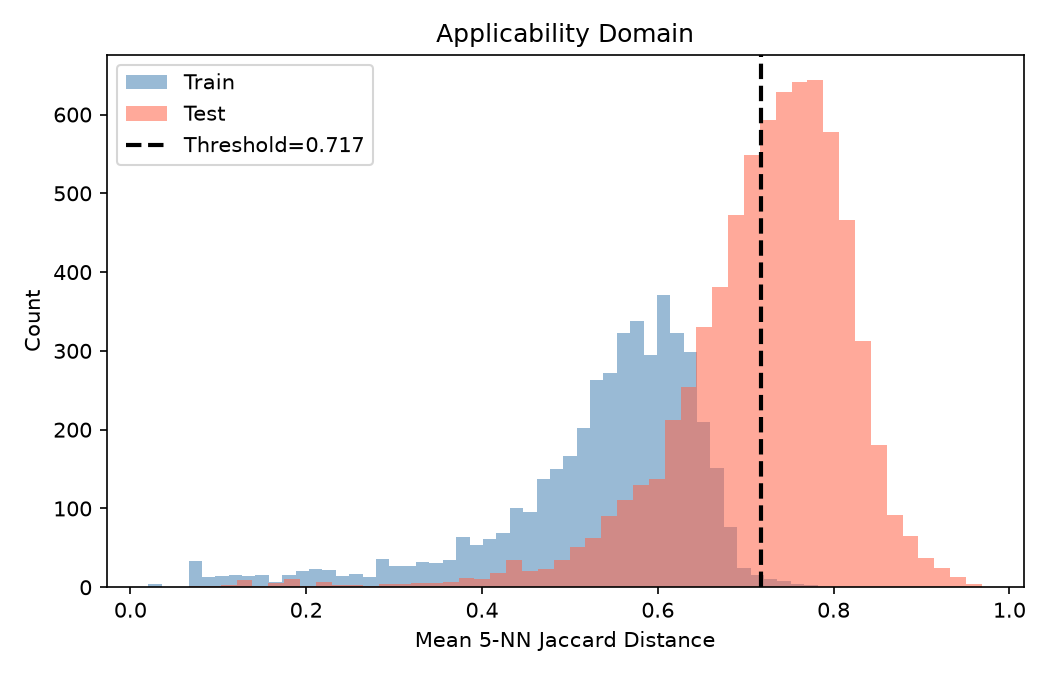

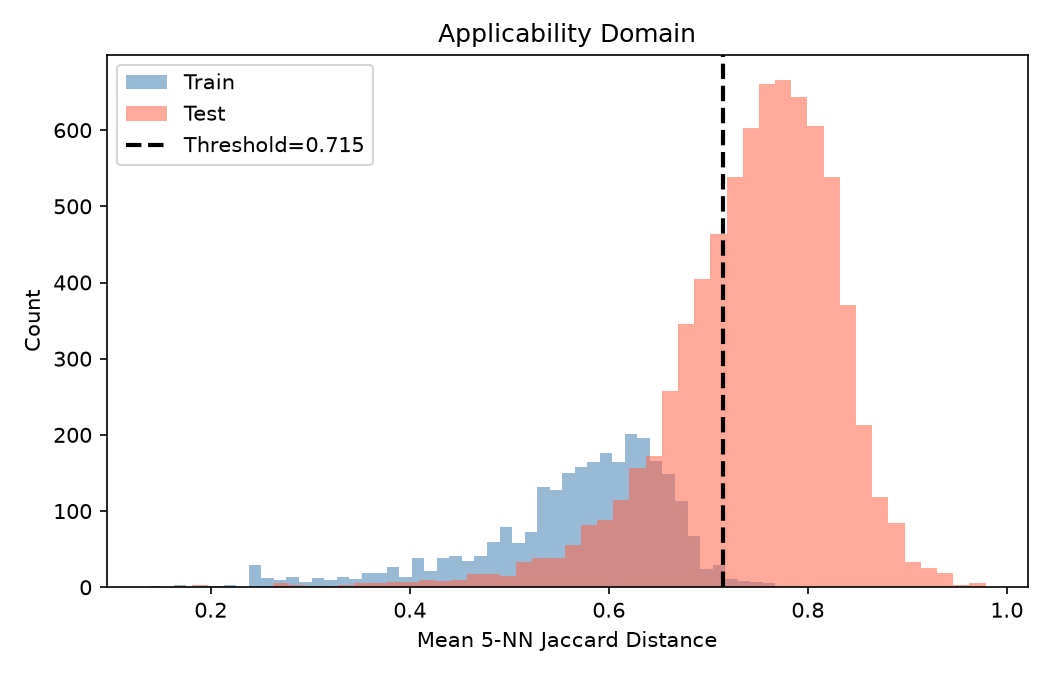

saved -> /Users/yamini/Desktop/projects/qsar casepase/qsar_prediction/Rebuttal/results/ad_cutoff_sweep_AID_654_1347034.png
saved -> /Users/yamini/Desktop/projects/qsar casepase/qsar_prediction/Rebuttal/results/ad_cutoff_sweep_AID_1347037.png


In [7]:
PRIMARY_K = 1.5  # matches the manuscript's original single-value AD analysis

for label in CASPASE_ASSAYS:
    md_tr_all = pooled_distances[label]['train']
    md_te_all = pooled_distances[label]['test']
    thr = md_tr_all.mean() + PRIMARY_K * md_tr_all.std()
    in_ad = md_te_all <= thr
    pct_in, pct_out = in_ad.mean() * 100, (1 - in_ad.mean()) * 100
    n_test = len(md_te_all)

    fig, ax = plt.subplots(figsize=(7, 4.5))
    ax.hist(md_tr_all, bins=50, alpha=0.55, color='steelblue', label='Train')
    ax.hist(md_te_all, bins=50, alpha=0.55, color='tomato', label='Test')
    ax.axvline(thr, color='black', linestyle='--', lw=2, label=f'Threshold={thr:.3f}')
    ax.set_xlabel('Mean 5-NN Jaccard Distance')
    ax.set_ylabel('Count')
    ax.set_title('Applicability Domain')
    ax.legend()
    fig.tight_layout()
    fname = label.split(' ')[0].replace('+', '_').replace('/', '_')
    fig.savefig(os.path.join(OUT_DIR, f'ad_histogram_{fname}.png'), dpi=150)
    plt.close(fig)
    print(f'{label}: {n_test:,} test compounds -- within ({pct_in:.1f}%) and outside ({pct_out:.1f}%) the AD '
          f'at threshold={thr:.3f}  -> saved ad_histogram_{fname}.png')

## Step 5 — where does the manuscript's k=1.5 ("0.65"-style) cutoff sit?

Prints the k=1.5 row explicitly (the multiplier used in the original single-value AD analysis) alongside the full sweep, so the response letter can quote both the original operating point and its neighbors on the curve.

In [8]:
cols = ['Assay', 'SD_multiplier', 'Threshold_Mean', 'Coverage_pct_Mean', 'Coverage_pct_SD',
        'ROC_AUC_Mean', 'ROC_AUC_CI95_Low', 'ROC_AUC_CI95_High']
print(ad_summary[cols].to_string(index=False))

AID_654+1347034 (Caspase-3/7, HepG2): 7,285 test compounds -- within (41.7%) and outside (58.3%) the AD at threshold=0.717  -> saved ad_histogram_AID_654_1347034.png
AID_1347037 (Caspase-3/7, CHO-K1): 7,496 test compounds -- within (30.6%) and outside (69.4%) the AD at threshold=0.715  -> saved ad_histogram_AID_1347037.png
                               Assay  SD_multiplier  Threshold_Mean  Coverage_pct_Mean  Coverage_pct_SD  ROC_AUC_Mean  ROC_AUC_CI95_Low  ROC_AUC_CI95_High
   AID_1347037 (Caspase-3/7, CHO-K1)            0.5        0.615150           6.977018         0.921879      0.917431          0.859824           0.975038
   AID_1347037 (Caspase-3/7, CHO-K1)            1.0        0.664730          14.367512         1.288567      0.911465          0.859197           0.963733
   AID_1347037 (Caspase-3/7, CHO-K1)            1.5        0.714310          30.321478         3.976172      0.889865          0.839617           0.940113
   AID_1347037 (Caspase-3/7, CHO-K1)            2.0    